In [1]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Conv2D,MaxPooling2D,Flatten,Dense

I0000 00:00:1791888420.535185     561 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791888421.057345     561 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791888422.980810     561 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
import matplotlib.pyplot as plt
from PIL import Image

In [3]:
# windows formate
# test_path = r"\mnt\C\Users\sharm\OneDrive\Desktop\code\deep learning\DogVsCat_Classification\datasets\test"
# train_path = r"\mnt\C\Users\sharm\OneDrive\Desktop\code\deep learning\DogVsCat_Classification\datasets\train"

# ubuntu formate
test_path = "/mnt/c/Users/sharm/OneDrive/Desktop/code/deep learning/DogVsCat_Classification/datasets/test"
train_path = "/mnt/c/Users/sharm/OneDrive/Desktop/code/deep learning/DogVsCat_Classification/datasets/train"


# load dataset 

In [4]:
train_ds = keras.utils.image_dataset_from_directory(
    directory = train_path,
    labels = 'inferred',
    label_mode = 'int',
    batch_size = 15,
    image_size = (256,256),
    shuffle = True
)

validation_ds = keras.utils.image_dataset_from_directory(
    directory = test_path,
    labels = 'inferred',
    label_mode = 'int',
    batch_size = 15,
    image_size = (256,256),
    shuffle = True
)

Found 20000 files belonging to 2 classes.


I0000 00:00:1791888457.046241     561 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Found 5000 files belonging to 2 classes.


# data preprocessing (normalization)

In [5]:
def process(image,label):
    image = tf.cast(image/256,tf.float32)
    return image,label

train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

# CNNs model 

In [6]:
model = Sequential()

# conv1
model.add(Conv2D(32,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3)))
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

# conv2
model.add(Conv2D(64,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

# conv3
model.add(Conv2D(128,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Flatten())

# fully connented layers
model.add(Dense(128,activation='relu'))
model.add(Dense(64,activation='relu'))

# output layers
model.add(Dense(1,activation='sigmoid'))

/home/vikas/tf-gpu/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,297 (56.64 MB)

 Trainable params: 14,847,297 (56.64 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [9]:
history = model.fit(train_ds,epochs=5,validation_data=validation_ds)

Epoch 1/5


/home/vikas/tf-gpu/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791888505.510680     561 service.cc:154] XLA service 0x42a464d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791888505.510736     561 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6 (Driver: 13.3.0[610.60.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791888505.542713     561 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791888506.160044     561 cuda_dnn.cc:442] Loaded cuDNN version 92700


   3/1334 ━━━━━━━━━━━━━━━━━━━━ 1:12 55ms/step - accuracy: 0.4889 - loss: 1.2352

I0000 00:00:1791888511.845534     561 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1334/1334 ━━━━━━━━━━━━━━━━━━━━ 91s 63ms/step - accuracy: 0.6119 - loss: 0.6525 - val_accuracy: 0.6928 - val_loss: 0.5986
Epoch 2/5
1334/1334 ━━━━━━━━━━━━━━━━━━━━ 79s 59ms/step - accuracy: 0.7356 - loss: 0.5257 - val_accuracy: 0.7390 - val_loss: 0.5225
Epoch 3/5
1334/1334 ━━━━━━━━━━━━━━━━━━━━ 80s 60ms/step - accuracy: 0.8178 - loss: 0.3932 - val_accuracy: 0.7572 - val_loss: 0.5514
Epoch 4/5
1334/1334 ━━━━━━━━━━━━━━━━━━━━ 79s 60ms/step - accuracy: 0.9007 - loss: 0.2365 - val_accuracy: 0.7334 - val_loss: 0.7770
Epoch 5/5
1334/1334 ━━━━━━━━━━━━━━━━━━━━ 80s 60ms/step - accuracy: 0.9508 - loss: 0.1282 - val_accuracy: 0.7384 - val_loss: 0.9322


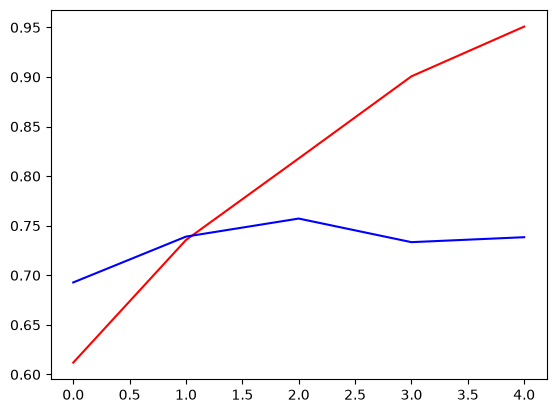

In [10]:
plt.plot(history.history['accuracy'] , color='red')
plt.plot(history.history['val_accuracy'],color='blue')

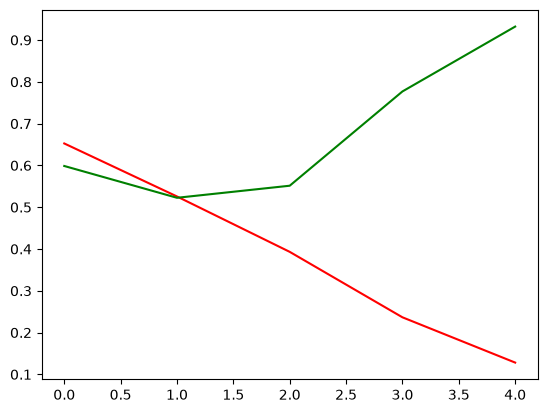

In [11]:
plt.plot(history.history['loss'],color = 'red')
plt.plot(history.history['val_loss'],color='green')

In [12]:
from keras.layers import BatchNormalization,Dropout

In [13]:
# control overlapping

In [14]:
model = Sequential()

# conv1
model.add(Conv2D(32,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

# conv2
model.add(Conv2D(64,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

# conv3
model.add(Conv2D(128,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Flatten())

# fully connented layers
model.add(Dense(128,activation='relu'))
model.add(Dropout(0.1))

model.add(Dense(64,activation='relu'))
model.add(Dropout(0.1))
# output layers
model.add(Dense(1,activation='sigmoid'))

In [15]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,193 (56.64 MB)

 Trainable params: 14,847,745 (56.64 MB)

 Non-trainable params: 448 (1.75 KB)

In [16]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [17]:
history = model.fit(train_ds, epochs=5, validation_data=validation_ds)

Epoch 1/5
1334/1334 ━━━━━━━━━━━━━━━━━━━━ 98s 71ms/step - accuracy: 0.6154 - loss: 1.1759 - val_accuracy: 0.6806 - val_loss: 0.5874
Epoch 2/5
1334/1334 ━━━━━━━━━━━━━━━━━━━━ 91s 68ms/step - accuracy: 0.7228 - loss: 0.5538 - val_accuracy: 0.7210 - val_loss: 0.5417
Epoch 3/5
1334/1334 ━━━━━━━━━━━━━━━━━━━━ 92s 69ms/step - accuracy: 0.7746 - loss: 0.4766 - val_accuracy: 0.7872 - val_loss: 0.4529
Epoch 4/5
1334/1334 ━━━━━━━━━━━━━━━━━━━━ 92s 69ms/step - accuracy: 0.8163 - loss: 0.4042 - val_accuracy: 0.7778 - val_loss: 0.4771
Epoch 5/5
1334/1334 ━━━━━━━━━━━━━━━━━━━━ 91s 68ms/step - accuracy: 0.8634 - loss: 0.3210 - val_accuracy: 0.7992 - val_loss: 0.4823


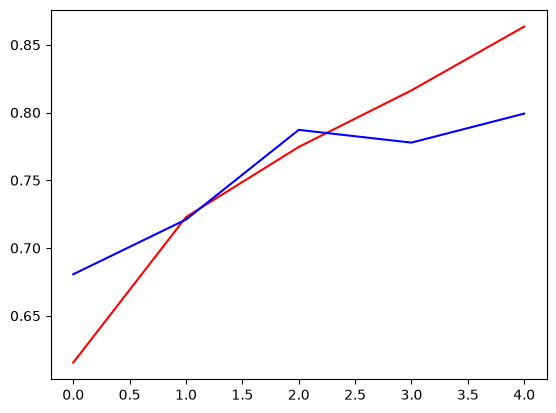

In [18]:
plt.plot(history.history['accuracy'] , color='red')
plt.plot(history.history['val_accuracy'],color='blue')

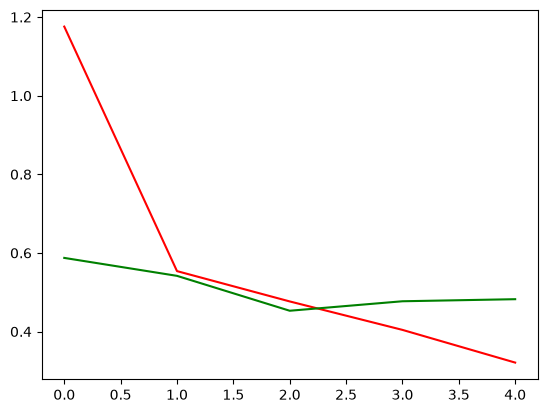

In [19]:
plt.plot(history.history['loss'],color = 'red')
plt.plot(history.history['val_loss'],color='green')